In [43]:
# install packages, if necessary (usually only for colab kernel)
import sys
from pathlib import Path

!pip install cheetah-accelerator
!pip install neuraloperator
!pip install scikit-learn
!pip install pandas

In [44]:
# if running in Google Colab, install google-colab package and mount Google Drive
if 'google.colab' in sys.modules:
    !pip install google-colab
    from google.colab import drive
    drive.mount("/content/drive")
    OUT_DIR = Path("/content/drive/MyDrive/Masterarbeit")  # Ordner nach Wunsch
else:
    OUT_DIR = Path(".")
OUT_DIR.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [45]:
# import main packages for this work
import numpy as np
import matplotlib.pyplot as plt
import cheetah
import torch
import neuralop

# import some neuralop modules directly for convenience
from neuralop.models import FNO
from neuralop.training import AdamW
from neuralop.data.datasets import load_darcy_flow_small
from neuralop.utils import count_model_params
from neuralop import LpLoss, H1Loss

In [46]:
# set device-agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"

In [47]:
def plot_predictions(model, test_samples, data_processor):
    fig = plt.figure(figsize=(7, 7))
    for index in range(3):
        data = test_samples[index]
        data = data_processor.preprocess(data, batched=False)

        # Input
        x = data["x"]
        # Ground-truth output
        y = data["y"]
        # Model prediction
        with torch.no_grad():                 # no gradients needed for plotting
            out = model(x.unsqueeze(0))

        x, y, out = (t.detach().cpu().numpy() for t in (x, y, out))
        # Plot input
        ax = fig.add_subplot(3, 3, index * 3 + 1)
        ax.imshow(x[0], cmap="gray")
        if index == 0:
            ax.set_title("Input x")
        plt.xticks([], [])
        plt.yticks([], [])

        # Plot ground-truth output
        ax = fig.add_subplot(3, 3, index * 3 + 2)
        ax.imshow(y.squeeze())
        if index == 0:
            ax.set_title("Ground-truth output")
        plt.xticks([], [])
        plt.yticks([], [])

        # Plot model prediction
        ax = fig.add_subplot(3, 3, index * 3 + 3)
        ax.imshow(out.squeeze())
        if index == 0:
            ax.set_title("Model prediction")
        plt.xticks([], [])
        plt.yticks([], [])

    fig.suptitle("FNO predictions on 16x16 Darcy-Flow data", y=0.98)
    plt.tight_layout()
    fig.show()

In [48]:
model = FNO(
    n_modes=(8, 8),
    in_channels=1,
    out_channels=1,
    hidden_channels=24,
    projection_channel_ratio=2,
).to(device)

In [49]:
model.save_checkpoint(save_folder=str(OUT_DIR) + '/checkpoints/', save_name='example_fno')

In [53]:
load_model = FNO.from_checkpoint(save_folder=str(OUT_DIR) + '/checkpoints/', save_name='example_fno').to(device)

In [54]:
train_loader, test_loaders, data_processor = load_darcy_flow_small(
    n_train=1000,
    batch_size=64,
    n_tests=[100, 50],
    test_resolutions=[16, 32],
    test_batch_sizes=[32, 32],
)
data_processor = data_processor.to(device)

Loading test db for resolution 16 with 100 samples 
Loading test db for resolution 32 with 50 samples 


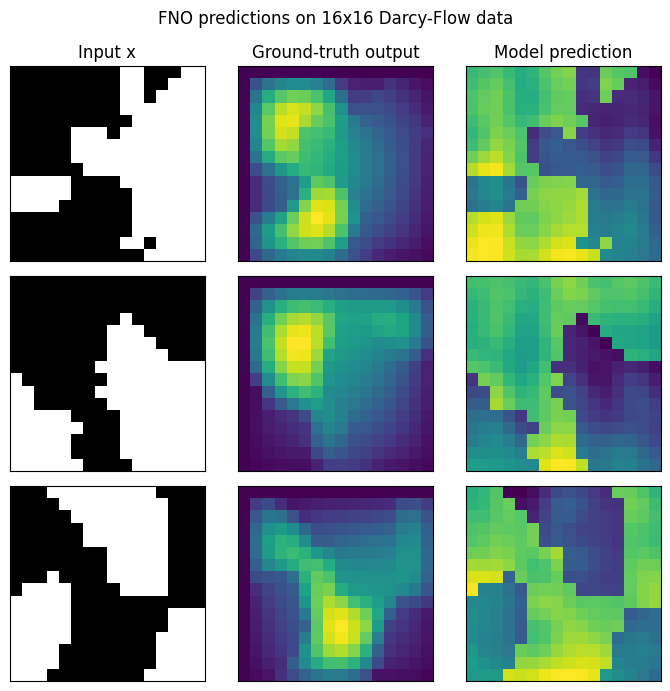

In [ ]:
# plot before training
test_samples = test_loaders[16].dataset
plot_predictions(load_model, test_samples, data_processor)

In [56]:
optimizer = AdamW(model.parameters(), lr=1e-2, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

In [57]:
l2loss = LpLoss(d=2, p=2)  # L2 loss for function values
h1loss = H1Loss(d=2)  # H1 loss includes gradient information

train_loss = h1loss
eval_losses = {"h1": h1loss, "l2": l2loss}

In [58]:
from neuralop.training import Trainer

# Create the trainer
trainer = Trainer(
    model=model,
    n_epochs=15,
    device=device,
    data_processor=data_processor,
    wandb_log=False,  # Disable Weights & Biases logging for this tutorial
    eval_interval=5,  # Evaluate every 5 epochs
    use_distributed=False,  # Single GPU/CPU training
    verbose=True,  # Print training progress
)

# train the model
trainer.train(
   train_loader=train_loader,
   test_loaders=test_loaders,
   optimizer=optimizer,
   scheduler=scheduler,
   regularizer=False,
   training_loss=train_loss,
   eval_losses=eval_losses
)

Training on 1000 samples
Testing on [50, 50] samples         on resolutions [16, 32].
Raw outputs of shape torch.Size([64, 1, 16, 16])


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/module.py:1790: UserWarning: FNO.forward() received unexpected keyword arguments: ['y']. These arguments will be ignored.
  return forward_call(*args, **kwargs)
/usr/local/lib/python3.13/dist-packages/neuralop/training/trainer.py:536: UserWarning: H1Loss.__call__() received unexpected keyword arguments: ['x']. These arguments will be ignored.
  loss += training_loss(out, **sample)


[0] time=0.35, avg_loss=0.8001, train_err=50.0046


/usr/local/lib/python3.13/dist-packages/neuralop/training/trainer.py:581: UserWarning: LpLoss.__call__() received unexpected keyword arguments: ['x']. These arguments will be ignored.
  val_loss = loss(out, **sample)


Eval: 16_h1=0.5845, 16_l2=0.5815, 32_h1=0.6816, 32_l2=0.5875
[5] time=0.33, avg_loss=0.2660, train_err=16.6276
Eval: 16_h1=0.2628, 16_l2=0.1847, 32_h1=0.3865, 32_l2=0.2044
[10] time=0.32, avg_loss=0.2038, train_err=12.7365
Eval: 16_h1=0.2233, 16_l2=0.1467, 32_h1=0.3778, 32_l2=0.1727


{'train_err': 11.02478551864624,
 'avg_loss': 0.17639656829833986,
 'avg_lasso_loss': None,
 'epoch_train_time': 0.3236960159993032}

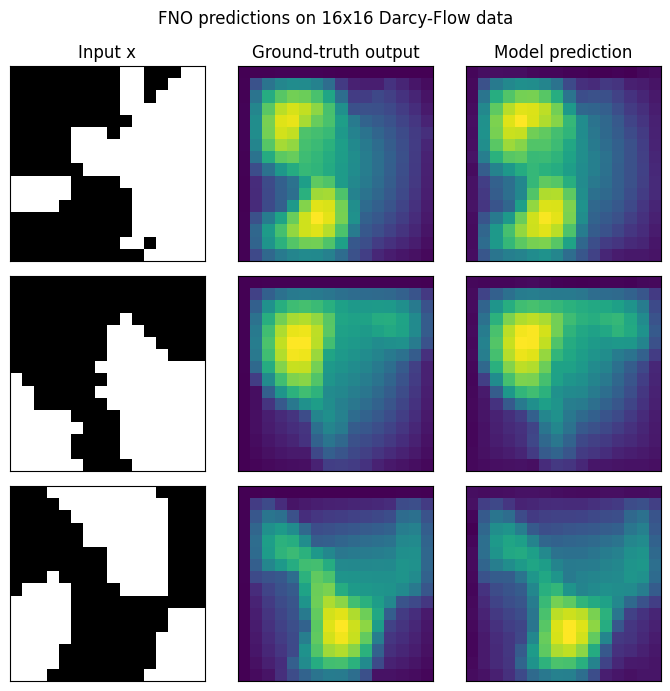

In [63]:
# plot after training
test_samples = test_loaders[16].dataset
plot_predictions(model, test_samples, data_processor)

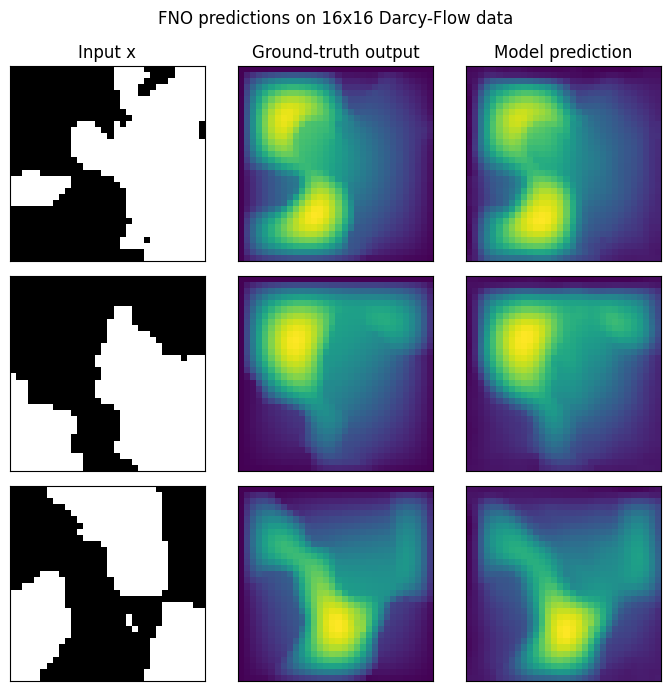

In [64]:
# plot zero shot super-resolution
test_samples = test_loaders[32].dataset
plot_predictions(model, test_samples, data_processor)